# Multi-fidelity inverse solve

Recover `h(x,y)` from a noisy temperature field, using **adaptive KSP tolerance as the
fidelity axis**: start with cheap, loosely-converged linear solves and tighten only when
the optimizer stalls.

Compare against a fixed tight-tolerance baseline on the same problem.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from benchmark_utils import BenchmarkCase, BenchmarkMethod, run_benchmark_case

## 1. The inverse problem

Same setup as `InverseSolve.ipynb`: recover a spatially-varying `h` from `T_obs`.

In [2]:
def h_true(x):
    return 1.0 + 6.0 * x[0] ** 2 + x[0] / (1.0 + 2.0 * x[1] ** 2)


def h0(x):
    return 2.0 + 3.0 * x[0] ** 2 + x[0] / (4.0 + 3.0 * x[1] ** 2)


case = BenchmarkCase(
    name="smooth",
    h_true=h_true,
    h0=h0,
    nmesh=32,
    sigma=1e-3,
    alpha=1e-4,
    observation_noise=1e-3,
    observation_seed=0,
)

## 2. Fidelity schedule  ← the multi-fidelity block

`initial_rtol` sets the starting (cheap, low) fidelity. The controller tightens by
`tighten_factor` once the objective improves by less than `stall_rel_improve` over
`stall_iterations`, or after `rejection_iterations` short steps — down to `min_rtol`.

Forward and adjoint solves always share one tolerance, so the gradient stays consistent
with the objective.

In [3]:
MIT = 200  # equal iteration budget for both methods

ADAPTIVE = {
    "initial_rtol": 1e-5,     # start cheap
    "min_rtol": 1e-10,        # finest fidelity
    "tighten_factor": 0.1,    # one decade per tightening
    "stall_iterations": 3,    # stalled for this many iterations ...
    "stall_rel_improve": 5e-2,  # ... means < 5% objective improvement
    "rejection_iterations": 2,
    "rejected_step_threshold": 0.25,
}

baseline = BenchmarkMethod(
    name="fixed 1e-10",
    forward_petsc_opts={"ksp_rtol": 1e-10},
    mit=MIT,
)

adaptive = BenchmarkMethod(
    name="adaptive 1e-5 -> 1e-10",
    adaptive_ksp_rtol=ADAPTIVE,
    mit=MIT,
)

## 3. Run both

`reason` is TAO's `ConvergedReason`: positive means a tolerance was met, negative means
it stopped for another cause. **Read it before trusting any comparison** — a method that
quits early looks cheap for the wrong reason.

In [4]:
from petsc4py import PETSc

# Decode TAO's reason codes from PETSc itself rather than hard-coding them.
REASONS = {
    v: k
    for k, v in vars(PETSc.TAO.ConvergedReason).items()
    if isinstance(v, int) and not k.startswith("_")
}

results = {m.name: run_benchmark_case(case, m) for m in (baseline, adaptive)}

for name, r in results.items():
    s = r.summary
    print(
        f"{name:24s} KSP={s['total_ksp_iterations']:6d}  TAO={s['tao_iterations']:4d}  "
        f"J={s['final_objective']:.4e}  err={s['h_error_l2_rel']:.4f}  "
        f"{s['wall_time_s']:5.2f}s  "
        f"{REASONS.get(s['converged_reason'], s['converged_reason'])}"
    )

fixed 1e-10              KSP=  2814  TAO= 200  J=1.3459e-01  err=0.1212   0.91s  DIVERGED_MAXITS
adaptive 1e-5 -> 1e-10   KSP=   444  TAO=  54  J=1.5327e-01  err=0.1172   0.42s  DIVERGED_LS_FAILURE


## 4. Did the cheap fidelity pay off?

The claim worth testing is **comparable accuracy for less linear-solver work** — not a
lower objective, and not fewer iterations on their own.

In [5]:
b, a = results[baseline.name].summary, results[adaptive.name].summary

saving = 100 * (1 - a["total_ksp_iterations"] / b["total_ksp_iterations"])
print(f"KSP iterations  : {b['total_ksp_iterations']} -> {a['total_ksp_iterations']}"
      f"  ({saving:.0f}% less work)")
print(f"relative h error: {b['h_error_l2_rel']:.4f} -> {a['h_error_l2_rel']:.4f}")
print(f"tightenings     : {a['ksp_tightenings']}")
print(f"rtol schedule   : {[f'{r:.0e}' for r in a['ksp_rtol_history']]}")
print(f"fwd/adj rtol matched: "
      f"{np.isclose(a['final_forward_ksp_rtol'], a['final_adjoint_ksp_rtol'])}")

if a["h_error_l2_rel"] <= 1.05 * b["h_error_l2_rel"]:
    print(f"\n=> comparable accuracy for {saving:.0f}% less linear-solver work.")
else:
    print(f"\n=> WORSE accuracy -- the schedule is too aggressive for this problem.")

KSP iterations  : 2814 -> 444  (84% less work)
relative h error: 0.1212 -> 0.1172
tightenings     : 2
rtol schedule   : ['1e-05', '1e-06', '1e-07']
fwd/adj rtol matched: True

=> comparable accuracy for 84% less linear-solver work.


**Caveat, and it matters.** Neither method converges to a gradient tolerance here: the
baseline exhausts its iteration budget, and the adaptive run stops on line-search failure
once the loose gradient can no longer support a descent step. The adaptive run is a fair
win on *work for a given accuracy*, not a demonstration of convergence.

Starting looser (`initial_rtol=1e-4`) makes the line search fail almost immediately, at a
much worse objective — the schedule has a floor below which the gradient is too noisy to
optimize against.

## 5. Convergence and the fidelity ladder

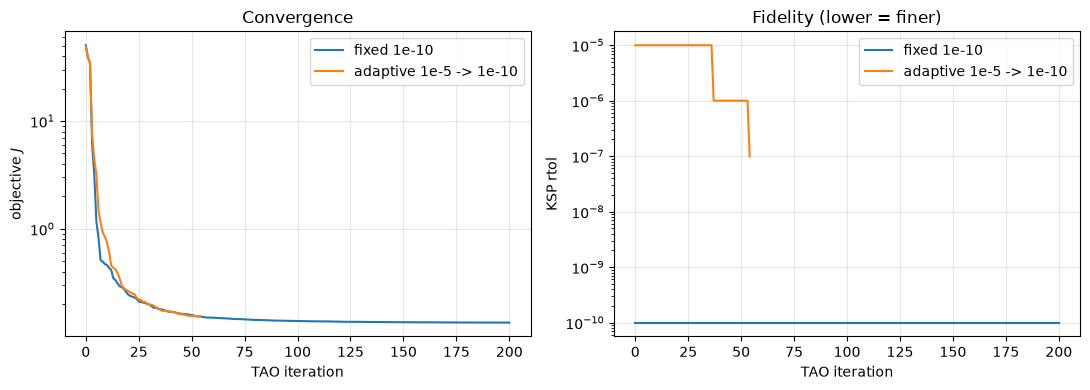

In [6]:
fig, (ax_obj, ax_rtol) = plt.subplots(1, 2, figsize=(11, 4))

for name, r in results.items():
    it = [row["tao_iter"] for row in r.trace]
    ax_obj.semilogy(it, [row["objective"] for row in r.trace], label=name)
    ax_rtol.semilogy(it, [row["forward_ksp_rtol"] for row in r.trace], label=name)

ax_obj.set(xlabel="TAO iteration", ylabel="objective $J$", title="Convergence")
ax_rtol.set(xlabel="TAO iteration", ylabel="KSP rtol", title="Fidelity (lower = finer)")
for ax in (ax_obj, ax_rtol):
    ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout()

## 6. Recovered conductivity

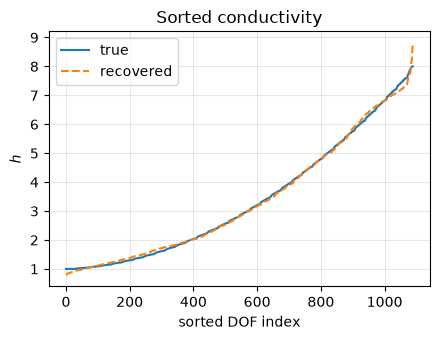

In [7]:
r = results[adaptive.name]
fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.plot(np.sort(r.truth), label="true")
ax.plot(np.sort(r.solution), "--", label="recovered")
ax.set(xlabel="sorted DOF index", ylabel="$h$", title="Sorted conductivity")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

## 7. Spectral fidelity: $T(k)$ and $r(k)$

Two scale-dependent diagnostics of the reconstruction, following the convention in
`EvaluateSolution.ipynb`:

- $T(k)=\sqrt{P_{\rm sol}(k)/P_{\rm true}(k)}$ — **amplitude bias**. $T<1$ means that
  scale is under-recovered (regularization smoothing); $T>1$ means noise is being fitted.
- $r(k)=P_{\rm sol\times true}(k)/\sqrt{P_{\rm sol}P_{\rm true}}$ — **phase coherence**.
  $r\to1$ means the mode is recovered in the right place; $r\to0$ means it is decorrelated
  from the truth even if its amplitude happens to be right.
- $T(k)-r(k)$ — **distance from optimal**. For the MMSE (Wiener) estimator
  $\hat{s}=\frac{S}{S+N}d$ the two coincide, $T=r=\sqrt{S/(S+N)}$. So $T>r$ means power
  was injected that does not correlate with the truth (over-fitting), and $T<r$ means
  recoverable signal was smoothed away (over-regularizing).

The three are not redundant: $r$ is invariant under rescaling the solution, so amplitude
and coherence are independent failures, and only their *difference* says which side of
optimal you are on.

In [8]:
from forward_solver import SteadyHeat2DForwardSolver

# DOF coordinates for this case (construction only, no solve).
probe = SteadyHeat2DForwardSolver(
    nmesh=case.nmesh, mesh_type=case.mesh_type,
    h=case.h0, q=case.q, DBC_value=case.T_bottom,
)
COORDS = probe.V.tabulate_dof_coordinates()[:, :2]
NGRID = case.nmesh + 1


def to_grid(values, coords=COORDS, n=NGRID):
    """DOF vector -> (n, n) array, rows = y, cols = x.

    Round before sorting: FEM dof coordinates carry floating-point jitter, so the
    raw values give 2n distinct coordinates instead of n and the sort scrambles.
    """
    c = np.round(coords, 12)
    return values[np.lexsort((c[:, 0], c[:, 1]))].reshape(n, n)


def power_spectrum(g1, g2=None, nbins=14):
    """Angle-averaged auto/cross spectrum; k in cycles per unit length.

    Binned only up to the Nyquist frequency. Beyond it the angular average samples
    just the corners of the 2D k-plane, where the field carries no real power --
    there T(k) diverges and r(k) turns negative, which is an artefact, not signal.
    """
    n = g1.shape[0]
    d = 1.0 / (n - 1)                      # physical spacing on the unit square
    k_nyq = 0.5 / d
    f1 = np.fft.rfft2(g1)
    f2 = f1 if g2 is None else np.fft.rfft2(g2)

    kk = np.hypot(*np.meshgrid(np.fft.fftfreq(n, d), np.fft.rfftfreq(n, d), indexing="ij"))
    keep = (kk > 0) & (kk <= k_nyq)
    edges = np.linspace(kk[keep].min(), k_nyq, nbins + 1)
    counts, _ = np.histogram(kk[keep], bins=edges)
    power, _ = np.histogram(kk[keep], bins=edges, weights=(f1 * f2.conj()).real[keep])

    ok = counts > 0
    return (0.5 * (edges[:-1] + edges[1:]))[ok], power[ok] / counts[ok]

fixed 1e-10              T: 0.954-1.219   r_min: 0.712   mean|T-r|: 0.211
adaptive 1e-5 -> 1e-10   T: 0.804-1.053   r_min: 0.714   mean|T-r|: 0.114


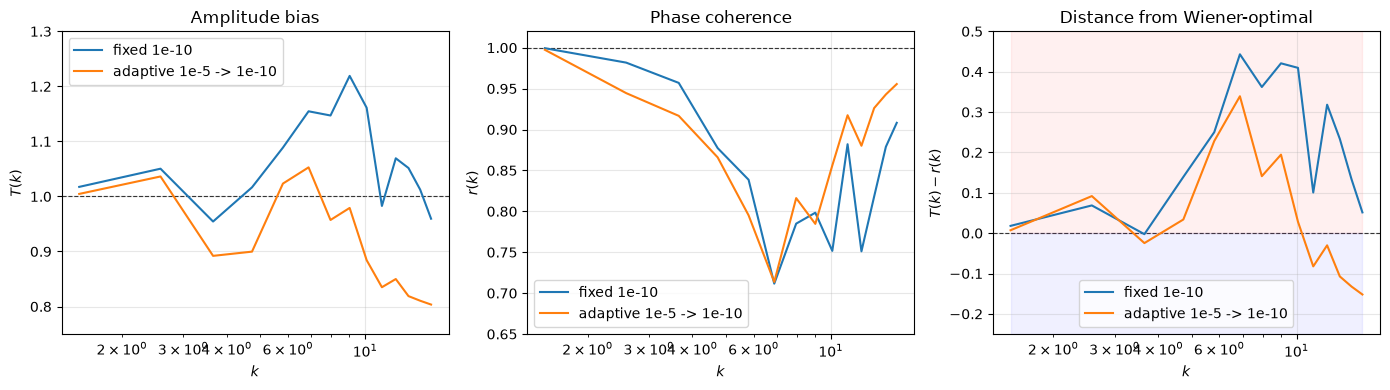

In [9]:
truth_grid = to_grid(results[baseline.name].truth)
k, P_true = power_spectrum(truth_grid)

spectra = {}
for name, res in results.items():
    sol_grid = to_grid(res.solution)
    _, P_sol = power_spectrum(sol_grid)
    _, P_x = power_spectrum(truth_grid, sol_grid)
    spectra[name] = (np.sqrt(P_sol / P_true), P_x / np.sqrt(P_true * P_sol))

fig, (ax_T, ax_r, ax_d) = plt.subplots(1, 3, figsize=(14, 4))
for name, (Tk, rk) in spectra.items():
    ax_T.semilogx(k, Tk, label=name)
    ax_r.semilogx(k, rk, label=name)
    ax_d.semilogx(k, Tk - rk, label=name)

ax_T.set(xlabel="$k$", ylabel="$T(k)$", title="Amplitude bias", ylim=(0.75, 1.30))
ax_r.set(xlabel="$k$", ylabel="$r(k)$", title="Phase coherence", ylim=(0.65, 1.02))
ax_d.set(xlabel="$k$", ylabel="$T(k)-r(k)$",
         title="Distance from Wiener-optimal", ylim=(-0.25, 0.5))
for ax, ref in ((ax_T, 1.0), (ax_r, 1.0), (ax_d, 0.0)):
    ax.axhline(ref, ls="--", c="k", zorder=0, lw=0.8)
    ax.legend()
    ax.grid(alpha=0.3)
ax_d.fill_between(k, 0, 0.5, alpha=0.06, color="r")
ax_d.fill_between(k, -0.25, 0, alpha=0.06, color="b")
fig.tight_layout()

for name, (Tk, rk) in spectra.items():
    print(f"{name:24s} T: {Tk.min():.3f}-{Tk.max():.3f}   r_min: {rk.min():.3f}   "
          f"mean|T-r|: {np.abs(Tk - rk).mean():.3f}")

### Reading the result

Both runs report the same scalar error (~0.12), but they fail in *opposite directions*:

- **fixed** sits in the red band, $T-r>0$ at every $k\gtrsim4$ — systematically
  over-fitting, injecting power that does not correlate with the truth.
- **adaptive** crosses zero: over-fitting at intermediate $k$, then $T-r<0$ at high $k$,
  where the coarse early fidelity has smoothed away recoverable signal.

By `mean|T-r|` the adaptive run is roughly twice as close to Wiener-optimal. But note it is
not *uniformly* better — at the smallest scales it has overcorrected past the optimum.
Being biased low helps only up to $T=r$; beyond that, signal is being discarded.

A scalar error norm cannot distinguish any of this, which is the point of Fourier space.

**Two caveats.** (1) Only $k\le k_{\rm Nyq}$ is shown: past Nyquist the angular average
samples the corners of the $k$-plane where the field carries no power, and $T(k)$ diverges
while $r(k)$ turns negative — artefact, not signal. (2) The FFT assumes periodicity, but
$h$ rises from 1 to about 8 across $x$, so the implied edge discontinuity leaks power
across all scales. Both fields carry that leakage, so it largely cancels in these ratios —
read them as a *relative* comparison between methods, not as absolute spectra.